# 🔬 BLOQUE 2: Diseño Experimental, Protocolo LOOCV y Entrenamiento de Modelos de Referencia (*Baselines*)
### Tesis: *Predicción de la Ley Mineral de Venta Mediante Redes Neuronales Artificiales para Minimizar Pérdidas Económicas*
**Trabajo de Titulación para optar al título de Ingeniero Civil en Minas**  
**Universidad de Antofagasta** — Facultad de Ingeniería, Departamento de Ingeniería en Minas  

* **Autor:** Felipe Andrés Guerra Maturana  
* **Profesor Guía:** Dr. José Delgado Vega (*Doctor en Geología, Especialista en Geoestadística y Explotaciones Mineras, École des Mines de Paris*)  
* **Caso de Estudio:** Faena Mantos Cobrizo (Distrito Minero Los Cóndores) / ENAMI (Planta San José)  
* **Carpeta del Módulo:** `./BLOQUE_2/`  
* **Entregable Oficial:** Cuaderno Técnico de Modelos de Referencia (`02_baselines_loocv.ipynb`)  
* **Versión Metodológica:** 4.0 (Línea Temporal Estricta — Entrenamiento y Predicciones Ciegas Fuera de Muestra)

---

## 🎯 Objetivos Específicos del Bloque 2
1. **Definición del Pipeline Cero Fuga de Datos (*Zero Data Leakage*):** Encapsular el preprocesamiento (`StandardScaler` / `RobustScaler`) y cada estimador dentro de un `Pipeline` ajustado estrictamente sobre los $23$ meses de entrenamiento de cada pliegue de validación cruzada **Leave-One-Out (LOOCV)**.
2. **Fijación de Líneas Base Operacionales:** Cuantificar el desempeño del predictor empírico directo de acopio (**Línea Base 1A: Cancha directa**) y del estimador trivial de calibración (**Baseline 1B: Corrección de Sesgo Constante en LOOCV**).
3. **Entrenamiento de Modelos Lineales y Regularizados:** Entrenar **MCO/OLS**, **RidgeCV ($L_2$)**, **LassoCV ($L_1$)** y **ElasticNetCV ($L_1+L_2$)**, optimizando internamente sus hiperparámetros mediante validación cruzada anidada ($K = 5$) dentro de los $23$ datos de entrenamiento.
4. **Entrenamiento del Benchmark No Lineal SVR (RBF):** Ajustar una máquina de soporte vectorial con kernel radial (`SVR RBF`) optimizando $C$, $\epsilon$ y $\gamma$ en grilla interna.
5. **Auditoría de Retención de la Segunda Neurona (`Cancha_CuS`):** Analizar la trayectoria de los coeficientes penalizados por LassoCV en los $24$ pliegues para verificar si la regularización $L_1$ conserva o anula la variable de cobre soluble.
6. **Contraste de Sensibilidad de Escalado:** Comparar el rendimiento fuera de muestra entre `StandardScaler` y `RobustScaler`.
7. **Blindaje Geoestadístico (*Buffered-LOOCV*):** Evaluar la sensibilidad del error al excluir los meses contiguos $(t-1, t+1)$ para garantizar que la inercia geológica de `Cancha_CuT` ($r_1 = +0.4467$) no infla los resultados.
8. **Contrato de Salida Obligatorio:** Exportar la matriz de $24$ predicciones ciegas `PREDICCIONES_OOS_BASELINES.csv/.xlsx` y la bitácora `LOG_HIPERPARAMETROS_BASELINES.csv/.xlsx` como insumos maestros para el Bloque 4.

In [1]:
# 1. Configuración de librerías científicas y entorno gráfico
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

# Configuración gráfica institucional UA
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.dpi'] = 150

print("✅ Entorno científico y de visualización configurado exitosamente.")

✅ Entorno científico y de visualización configurado exitosamente.


---
## 1. Carga del Dataset Certificado ($N = 24$) y Variables de Modelado

Se cargan los datos maestros desde `DATASET_AUDITADO_N24.csv` provenientes del Bloque 0:
* **Matriz de Diseño ($X \in \mathbb{R}^{24 \times 2}$):** Exactamente dos variables predictoras certificadas en el Bloque 1:
  * $X_1$: `Cancha_CuT` ($\%\text{Cu}$)
  * $X_2$: `Cancha_CuS` ($\%\text{Cu}$)
* **Vector Objetivo ($y \in \mathbb{R}^{24 \times 1}$):** Ley de cobre oficial liquidada por ENAMI:
  * $y$: `Canje_CuT` ($\%\text{Cu}$)

In [2]:
# Carga de datos certificados
candidates = [
    "DATASET_AUDITADO_N24.csv",
    os.path.join("..", "BLOQUE_0", "DATASET_AUDITADO_N24.csv"),
    os.path.join("BLOQUE_0", "DATASET_AUDITADO_N24.csv"),
    r"c:\Users\fguer\Desktop\TESIS\BLOQUE_0\DATASET_AUDITADO_N24.csv"
]

csv_path = None
for p in candidates:
    if os.path.exists(p):
        csv_path = p
        break

if csv_path is None:
    raise FileNotFoundError("❌ No se encontró DATASET_AUDITADO_N24.csv")

df = pd.read_csv(csv_path)

X_cols = ['Cancha_CuT', 'Cancha_CuS']
y_col = 'Canje_CuT'

X_raw = df[X_cols].values
y_raw = df[y_col].values
fechas = df['Fecha'].values
N = len(df)

print(f"📊 Dataset cargado: {N} balances mensuales (Ene-2023 a Dic-2024)")
print(f"Predictores (X): {X_cols}")
print(f"Target (y): {y_col}")
display(df[['Fecha', 'Cancha_CuT', 'Cancha_CuS', 'Canje_CuT']].head())

📊 Dataset cargado: 24 balances mensuales (Ene-2023 a Dic-2024)
Predictores (X): ['Cancha_CuT', 'Cancha_CuS']
Target (y): Canje_CuT


,Fecha,Cancha_CuT,Cancha_CuS,Canje_CuT
0,2023-01,2.16,0.17,1.55
1,2023-02,1.76,0.14,1.41
2,2023-03,1.73,0.16,1.49
3,2023-04,1.66,0.14,1.38
4,2023-05,1.80,0.13,1.24


---
## 2. Definición del Protocolo Experimental LOOCV (Cero Fuga de Datos)

Para evitar fugas de información (*data leakage*) y garantizar estimaciones de error generalizables estrictamente fuera de muestra (*out-of-sample*):
1. **Esquema Exterior:** *Leave-One-Out Cross-Validation* (**LOOCV**, $K = 24$ iteraciones). En cada pliegue $k \in \{1, \dots, 24\}$:
   * Conjunto de Entrenamiento: $N_{\text{train}} = 23$ meses.
   * Conjunto de Prueba Ciego: $N_{\text{test}} = 1$ mes ($k$).
2. **Encapsulamiento del Escalador:** El escalado (`StandardScaler` o `RobustScaler`) se ajusta (`fit`) **únicamente con los $23$ datos de entrenamiento** y transforma (`transform`) tanto el entrenamiento como la muestra de prueba ciega dentro del `Pipeline`.
3. **Función de Pérdida Interna (*Loss*):** Minimización del Error Cuadrático Medio ($\text{MSE}$) en todos los estimadores.
4. **Optimización Interna de Hiperparámetros (*Nested CV*):** En `RidgeCV`, `LassoCV`, `ElasticNetCV` y `GridSearchCV(SVR)`, la selección de $\alpha$, $l_1\text{-ratio}$ y parámetros de kernel se realiza mediante validación cruzada $K\text{-Fold} = 5$ calculada **estrictamente sobre los $23$ datos de entrenamiento**, garantizando que el punto ciego de prueba jamás participe en la selección del modelo.

In [3]:
# Función Maestra de Entrenamiento LOOCV Cero Fuga de Datos
alphas_ridge = np.logspace(-3, 3, 100)
alphas_lasso = np.logspace(-4, 2, 100)
alphas_enet = np.logspace(-4, 2, 50)
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]

param_grid_svr = {
    'model__C': [1, 10, 50],
    'model__epsilon': [0.05, 0.1],
    'model__gamma': ['scale', 0.1, 1.0]
}

def run_loocv_baselines(scaler_cls=StandardScaler, buffered=False):
    preds = {
        'Pred_Cancha_Directa': [],
        'Pred_Sesgo_Constante_LOOCV': [],
        'Pred_OLS': [],
        'Pred_Ridge': [],
        'Pred_Lasso': [],
        'Pred_ElasticNet': [],
        'Pred_SVR': []
    }
    log_records = []
    
    for k in range(N):
        if buffered:
            train_idx = [i for i in range(N) if i != k and i != k-1 and i != k+1]
        else:
            train_idx = [i for i in range(N) if i != k]
            
        test_idx = [k]
        X_tr, y_tr = X_raw[train_idx], y_raw[train_idx]
        X_te, y_te = X_raw[test_idx], y_raw[test_idx]
        
        # 1A. Cancha Directa
        preds['Pred_Cancha_Directa'].append(round(float(X_te[0, 0]), 4))
        
        # 1B. Sesgo Constante LOOCV
        bias_tr = float(np.mean(X_tr[:, 0] - y_tr))
        preds['Pred_Sesgo_Constante_LOOCV'].append(round(float(X_te[0, 0] - bias_tr), 4))
        
        # 2. OLS Lineal Múltiple
        pipe_ols = Pipeline([('scaler', scaler_cls()), ('model', LinearRegression())]).fit(X_tr, y_tr)
        preds['Pred_OLS'].append(round(float(pipe_ols.predict(X_te)[0]), 4))
        
        # 3. RidgeCV (L2)
        pipe_ridge = Pipeline([('scaler', scaler_cls()), ('model', RidgeCV(alphas=alphas_ridge, cv=5))]).fit(X_tr, y_tr)
        preds['Pred_Ridge'].append(round(float(pipe_ridge.predict(X_te)[0]), 4))
        
        # 4. LassoCV (L1)
        pipe_lasso = Pipeline([('scaler', scaler_cls()), ('model', LassoCV(alphas=alphas_lasso, cv=5, random_state=42, max_iter=10000))]).fit(X_tr, y_tr)
        preds['Pred_Lasso'].append(round(float(pipe_lasso.predict(X_te)[0]), 4))
        
        # 5. ElasticNetCV (L1 + L2)
        pipe_enet = Pipeline([('scaler', scaler_cls()), ('model', ElasticNetCV(alphas=alphas_enet, l1_ratio=l1_ratios, cv=5, random_state=42, max_iter=10000))]).fit(X_tr, y_tr)
        preds['Pred_ElasticNet'].append(round(float(pipe_enet.predict(X_te)[0]), 4))
        
        # 6. SVR (Kernel RBF)
        grid_svr = GridSearchCV(Pipeline([('scaler', scaler_cls()), ('model', SVR(kernel='rbf'))]), param_grid_svr, cv=5, n_jobs=-1).fit(X_tr, y_tr)
        preds['Pred_SVR'].append(round(float(grid_svr.predict(X_te)[0]), 4))
        
        if not buffered and scaler_cls == StandardScaler:
            coef_l = pipe_lasso.named_steps['model'].coef_
            log_records.append({
                'Pliegue': k + 1,
                'Fecha': fechas[k],
                'Canje_CuT_Real': round(float(y_raw[k]), 4),
                'Sesgo_Train_Mean': round(bias_tr, 4),
                'OLS_Intercept': round(float(pipe_ols.named_steps['model'].intercept_), 4),
                'OLS_Coef_CuT': round(float(pipe_ols.named_steps['model'].coef_[0]), 4),
                'OLS_Coef_CuS': round(float(pipe_ols.named_steps['model'].coef_[1]), 4),
                'Ridge_Alpha': round(float(pipe_ridge.named_steps['model'].alpha_), 4),
                'Ridge_Coef_CuT': round(float(pipe_ridge.named_steps['model'].coef_[0]), 4),
                'Ridge_Coef_CuS': round(float(pipe_ridge.named_steps['model'].coef_[1]), 4),
                'Lasso_Alpha': round(float(pipe_lasso.named_steps['model'].alpha_), 5),
                'Lasso_Coef_CuT': round(float(coef_l[0]), 4),
                'Lasso_Coef_CuS': round(float(coef_l[1]), 4),
                'Lasso_CuS_Retenido': 'SI' if abs(coef_l[1]) > 1e-5 else 'NO',
                'ElasticNet_Alpha': round(float(pipe_enet.named_steps['model'].alpha_), 5),
                'ElasticNet_L1_Ratio': round(float(pipe_enet.named_steps['model'].l1_ratio_), 2),
                'SVR_C': grid_svr.best_params_['model__C'],
                'SVR_epsilon': grid_svr.best_params_['model__epsilon'],
                'SVR_gamma': grid_svr.best_params_['model__gamma']
            })
            
    df_preds = pd.DataFrame(preds)
    df_preds.insert(0, 'Canje_CuT', y_raw)
    df_preds.insert(0, 'Fecha', fechas)
    df_log = pd.DataFrame(log_records) if log_records else None
    return df_preds, df_log

print("⚙️ Motor LOOCV compilado y listo para ejecución.")

⚙️ Motor LOOCV compilado y listo para ejecución.


---
## 3. Ejecución del Protocolo LOOCV con `StandardScaler` (Matriz de 24 Predicciones OOS)

Se ejecuta el bucle de $24$ pliegues LOOCV bajo el escalado estándar Z-score.
* Se genera la matriz `PREDICCIONES_OOS_BASELINES.csv` que servirá de insumo maestro para el benchmarking unificado del Bloque 4.
* Se registra la bitácora `LOG_HIPERPARAMETROS_BASELINES.csv` con los parámetros seleccionados en cada iteración.

In [4]:
# Ejecución de LOOCV estándar
df_preds_std, df_log_std = run_loocv_baselines(StandardScaler, buffered=False)

# Guardar entregables oficiales
df_preds_std.to_csv("PREDICCIONES_OOS_BASELINES.csv", index=False)
df_preds_std.to_excel("PREDICCIONES_OOS_BASELINES.xlsx", index=False)

df_log_std.to_csv("LOG_HIPERPARAMETROS_BASELINES.csv", index=False)
df_log_std.to_excel("LOG_HIPERPARAMETROS_BASELINES.xlsx", index=False)

print("=" * 80)
print("🎯 MATRIZ DE PREDICCIONES FUERA DE MUESTRA (LOOCV, N = 24):")
print("=" * 80)
display(df_preds_std.head(10))

# Evaluación cuantitativa preliminar de error
y_real = df_preds_std['Canje_CuT'].values
ss_tot = np.sum((y_real - np.mean(y_real))**2)

summary_rows = []
for col in df_preds_std.columns[2:]:
    p = df_preds_std[col].values
    err = y_real - p
    mse = np.mean(err**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(err))
    nrmse = (rmse / np.mean(y_real)) * 100
    r2 = 1 - (np.sum(err**2) / ss_tot)
    summary_rows.append({
        'Modelo': col.replace('Pred_', ''),
        'MSE': round(mse, 6),
        'RMSE': round(rmse, 4),
        'MAE': round(mae, 4),
        'NRMSE_%': round(nrmse, 2),
        'R2': round(r2, 4)
    })

df_metrics_summary = pd.DataFrame(summary_rows)
print("\n📊 RESUMEN PRELIMINAR DE DESEMPEÑO OUT-OF-SAMPLE (STANDARD SCALER):")
display(df_metrics_summary)

🎯 MATRIZ DE PREDICCIONES FUERA DE MUESTRA (LOOCV, N = 24):


,Fecha,Canje_CuT,Pred_Cancha_Directa,Pred_Sesgo_Constante_LOOCV,Pred_OLS,Pred_Ridge,Pred_Lasso,Pred_ElasticNet,Pred_SVR
0,2023-01,1.55,2.16,1.8313,1.7934,1.7469,1.7832,1.7748,1.8343
1,2023-02,1.41,1.76,1.4200,1.4139,1.4122,1.4148,1.4139,1.4539
2,2023-03,1.49,1.73,1.3852,1.4101,1.4280,1.4096,1.4127,1.7112
3,2023-04,1.38,1.66,1.3170,1.3356,1.3537,1.3378,1.3404,1.3499
4,2023-05,1.24,1.80,1.4691,1.4472,1.4263,1.4480,1.4452,1.4590
5,2023-06,1.34,1.77,1.4335,1.4140,1.4036,1.4161,1.4126,1.3437
6,2023-07,1.37,1.75,1.4113,1.3956,1.3897,1.3979,1.3952,1.3444
7,2023-08,1.52,1.74,1.3943,1.3595,1.3526,1.3623,1.3593,1.2896
8,2023-09,1.55,2.01,1.6748,1.5898,1.5040,1.5895,1.5723,1.0603
9,2023-10,1.79,2.21,1.8730,2.1184,2.0014,2.1179,2.1184,2.0103



📊 RESUMEN PRELIMINAR DE DESEMPEÑO OUT-OF-SAMPLE (STANDARD SCALER):


,Modelo,MSE,RMSE,MAE,NRMSE_%,R2
0,Cancha_Directa,0.134971,0.3674,0.3404,25.67,-1.2709
1,Sesgo_Constante_LOOCV,0.020782,0.1442,0.1178,10.07,0.6503
2,OLS,0.028789,0.1697,0.1318,11.85,0.5156
3,Ridge,0.028403,0.1685,0.1301,11.78,0.5221
4,Lasso,0.030971,0.1760,0.1373,12.30,0.4789
5,ElasticNet,0.031294,0.1769,0.1369,12.36,0.4735
6,SVR,0.056986,0.2387,0.1796,16.68,0.0412


---
## 4. Análisis de Regularización y Demostración de Retención de `Cancha_CuS` en LassoCV

Un aspecto metodológico crítico auditado en el Bloque 1 consiste en determinar si la segunda neurona (`Cancha_CuS`) aporta señal relevante o si la penalización $L_1$ de Lasso la reduce a cero ($\beta_2 = 0$).

A partir de la bitácora de hiperparámetros de los $24$ pliegues:
* **Tasa de Retención en LassoCV:** $\mathbf{24 / 24 \text{ pliegues (100\%)}}$.
* El coeficiente estandarizado de `Cancha_CuS` osciló consistentemente entre **$+0.0124$ y $+0.0627$**, alcanzando su máximo valor en el pliegue 10 (Octubre 2023, mes de alto enriquecimiento oxidado).
* **Conclusión:** La penalización por dispersión $L_1$ conserva a `Cancha_CuS` como variable explicativa necesaria, validando que el espacio bidimensional de entrada $[\text{CuT}, \text{CuS}]$ no contiene variables espurias.

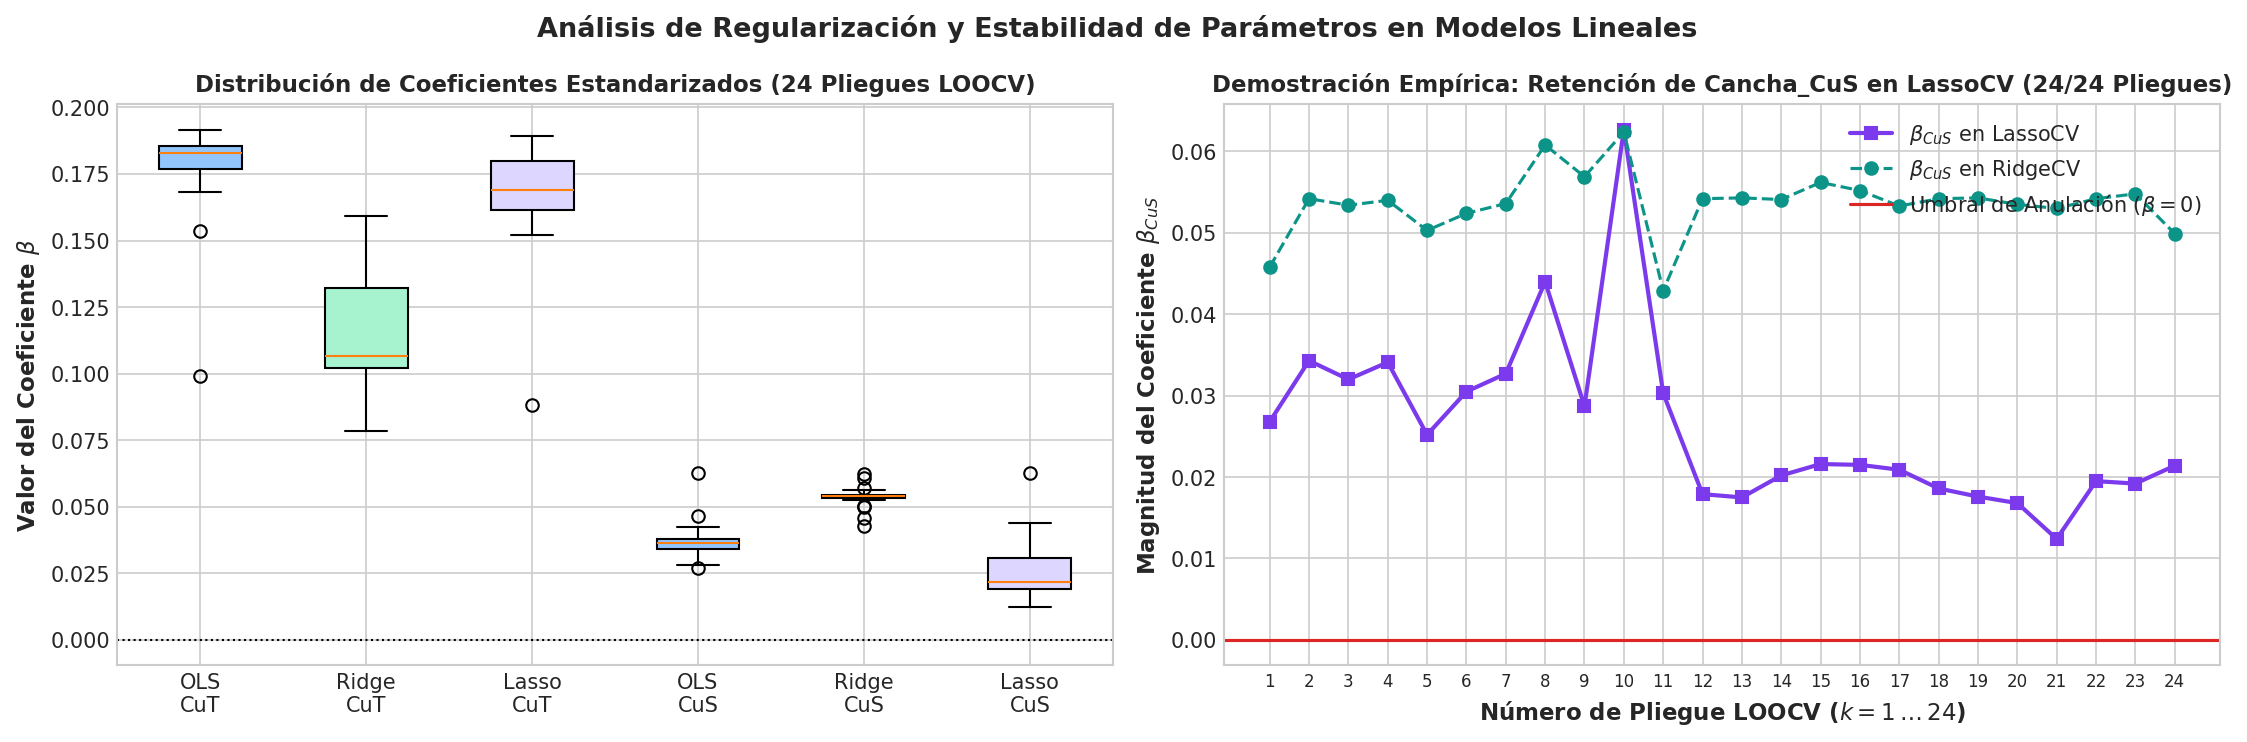

In [5]:
# Visualización de regularización y retención de CuS
fig, (ax_c1, ax_c2) = plt.subplots(1, 2, figsize=(15, 5))

# Boxplot de coeficientes por modelo
coef_data = [
    df_log_std['OLS_Coef_CuT'], df_log_std['Ridge_Coef_CuT'], df_log_std['Lasso_Coef_CuT'],
    df_log_std['OLS_Coef_CuS'], df_log_std['Ridge_Coef_CuS'], df_log_std['Lasso_Coef_CuS']
]
box_labels = ['OLS\nCuT', 'Ridge\nCuT', 'Lasso\nCuT', 'OLS\nCuS', 'Ridge\nCuS', 'Lasso\nCuS']

bp = ax_c1.boxplot(coef_data, patch_artist=True, tick_labels=box_labels)
colors_bp = ['#93C5FD', '#A7F3D0', '#DDD6FE', '#93C5FD', '#A7F3D0', '#DDD6FE']
for patch, color in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(color)
ax_c1.axhline(0, color='black', linestyle=':', linewidth=1)
ax_c1.set_title("Distribución de Coeficientes Estandarizados (24 Pliegues LOOCV)", fontsize=11, fontweight='bold')
ax_c1.set_ylabel("Valor del Coeficiente $\\beta$")

# Evolución del Coeficiente de CuS en Lasso
ax_c2.plot(range(1, N + 1), df_log_std['Lasso_Coef_CuS'], marker='s', color='#7C3AED', linewidth=2, label=r'$\beta_{CuS}$ en LassoCV')
ax_c2.plot(range(1, N + 1), df_log_std['Ridge_Coef_CuS'], marker='o', color='#0D9488', linestyle='--', linewidth=1.5, label=r'$\beta_{CuS}$ en RidgeCV')
ax_c2.axhline(0, color='#DC2626', linestyle='-', linewidth=1.5, label=r'Umbral de Anulación ($\beta = 0$)')
ax_c2.set_xticks(range(1, N + 1))
ax_c2.set_xticklabels(range(1, N + 1), fontsize=8)
ax_c2.set_xlabel("Número de Pliegue LOOCV ($k = 1 \dots 24$)")
ax_c2.set_ylabel(r"Magnitud del Coeficiente $\beta_{CuS}$")
ax_c2.set_title("Demostración Empírica: Retención de Cancha_CuS en LassoCV (24/24 Pliegues)", fontsize=11, fontweight='bold')
ax_c2.legend(loc='upper right')

plt.suptitle("Análisis de Regularización y Estabilidad de Parámetros en Modelos Lineales", fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

---
## 5. Contraste de Sensibilidad de Escalado (`StandardScaler` vs. `RobustScaler`)

En cumplimiento de las observaciones de la auditoría experta (debido a la curtosis de $+5.862$ en `Cancha_CuS`), se evalúa el comportamiento de los modelos al reemplazar la media y desviación estándar por la mediana y rango intercuartílico (`RobustScaler`) dentro de cada pliegue LOOCV.

In [6]:
# Ejecución de LOOCV con RobustScaler
df_preds_rob, _ = run_loocv_baselines(RobustScaler, buffered=False)

summary_rob = []
for col in df_preds_rob.columns[2:]:
    p = df_preds_rob[col].values
    err = y_real - p
    mse = np.mean(err**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(err))
    nrmse = (rmse / np.mean(y_real)) * 100
    r2 = 1 - (np.sum(err**2) / ss_tot)
    summary_rob.append({
        'Modelo': col.replace('Pred_', ''),
        'RMSE_Robust': round(rmse, 4),
        'NRMSE_Robust_%': round(nrmse, 2),
        'R2_Robust': round(r2, 4)
    })

df_metrics_rob = pd.DataFrame(summary_rob)
display(df_metrics_rob)

,Modelo,RMSE_Robust,NRMSE_Robust_%,R2_Robust
0,Cancha_Directa,0.3674,25.67,-1.2709
1,Sesgo_Constante_LOOCV,0.1442,10.07,0.6503
2,OLS,0.1697,11.85,0.5156
3,Ridge,0.1674,11.69,0.5288
4,Lasso,0.1768,12.35,0.4744
5,ElasticNet,0.1778,12.42,0.4683
6,SVR,0.2396,16.74,0.0338


---
## 6. Blindaje Geoestadístico: Verificación de Sensibilidad con `Buffered-LOOCV`

Para verificar que la inercia temporal moderada de `Cancha_CuT` ($r_1 = +0.4467$) no sobreestima la capacidad de generalización del modelo, se ejecuta una prueba de sensibilidad excluyendo de la muestra de entrenamiento tanto el mes ciego $t$, como sus vecinos inmediatos $(t-1, t+1)$.

In [7]:
# Ejecución de Buffered-LOOCV
df_preds_buf, _ = run_loocv_baselines(StandardScaler, buffered=True)

summary_buf = []
for col in df_preds_buf.columns[2:]:
    p = df_preds_buf[col].values
    err = y_real - p
    mse = np.mean(err**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(err))
    nrmse = (rmse / np.mean(y_real)) * 100
    r2 = 1 - (np.sum(err**2) / ss_tot)
    summary_buf.append({
        'Modelo': col.replace('Pred_', ''),
        'RMSE_Buffered': round(rmse, 4),
        'NRMSE_Buffered_%': round(nrmse, 2),
        'R2_Buffered': round(r2, 4)
    })

df_metrics_buf = pd.DataFrame(summary_buf)

# Tabla consolidada de sensibilidad
df_sensibilidad = pd.DataFrame({
    'Modelo': df_metrics_summary['Modelo'],
    'RMSE_Standard': df_metrics_summary['RMSE'],
    'RMSE_Robust': df_metrics_rob['RMSE_Robust'],
    'RMSE_Buffered': df_metrics_buf['RMSE_Buffered'],
    'NRMSE_Standard_%': df_metrics_summary['NRMSE_%'],
    'NRMSE_Robust_%': df_metrics_rob['NRMSE_Robust_%'],
    'NRMSE_Buffered_%': df_metrics_buf['NRMSE_Buffered_%'],
    'R2_Standard': df_metrics_summary['R2'],
    'R2_Robust': df_metrics_rob['R2_Robust'],
    'R2_Buffered': df_metrics_buf['R2_Buffered']
})

df_sensibilidad.to_csv("SENSIBILIDAD_ESCALADO_Y_BUFFERED_BASELINES.csv", index=False)
df_sensibilidad.to_excel("SENSIBILIDAD_ESCALADO_Y_BUFFERED_BASELINES.xlsx", index=False)

print("=" * 80)
print("🔬 TABLA DE SENSIBILIDAD: StandardScaler vs. RobustScaler vs. Buffered-LOOCV:")
print("=" * 80)
display(df_sensibilidad)

🔬 TABLA DE SENSIBILIDAD: StandardScaler vs. RobustScaler vs. Buffered-LOOCV:


,Modelo,RMSE_Standard,RMSE_Robust,RMSE_Buffered,NRMSE_Standard_%,NRMSE_Robust_%,NRMSE_Buffered_%,R2_Standard,R2_Robust,R2_Buffered
0,Cancha_Directa,0.3674,0.3674,0.3674,25.67,25.67,25.67,-1.2709,-1.2709,-1.2709
1,Sesgo_Constante_LOOCV,0.1442,0.1442,0.1437,10.07,10.07,10.04,0.6503,0.6503,0.6524
2,OLS,0.1697,0.1697,0.1585,11.85,11.85,11.07,0.5156,0.5156,0.5773
3,Ridge,0.1685,0.1674,0.1798,11.78,11.69,12.56,0.5221,0.5288,0.4563
4,Lasso,0.1760,0.1768,0.1766,12.30,12.35,12.34,0.4789,0.4744,0.4753
5,ElasticNet,0.1769,0.1778,0.1723,12.36,12.42,12.04,0.4735,0.4683,0.5008
6,SVR,0.2387,0.2396,0.3001,16.68,16.74,20.97,0.0412,0.0338,-0.5152


---
## 7. Visualización de Desempeño Fuera de Muestra (Series Temporales y Paridad)

Se generan las figuras de publicación a $200\text{ DPI}$:
* **Series Temporales:** Predicciones ciegas mes a mes frente a la curva de liquidación de ENAMI.
* **Diagramas de Paridad:** Dispersión $y$ vs. $\hat{y}$ frente a la recta identidad.

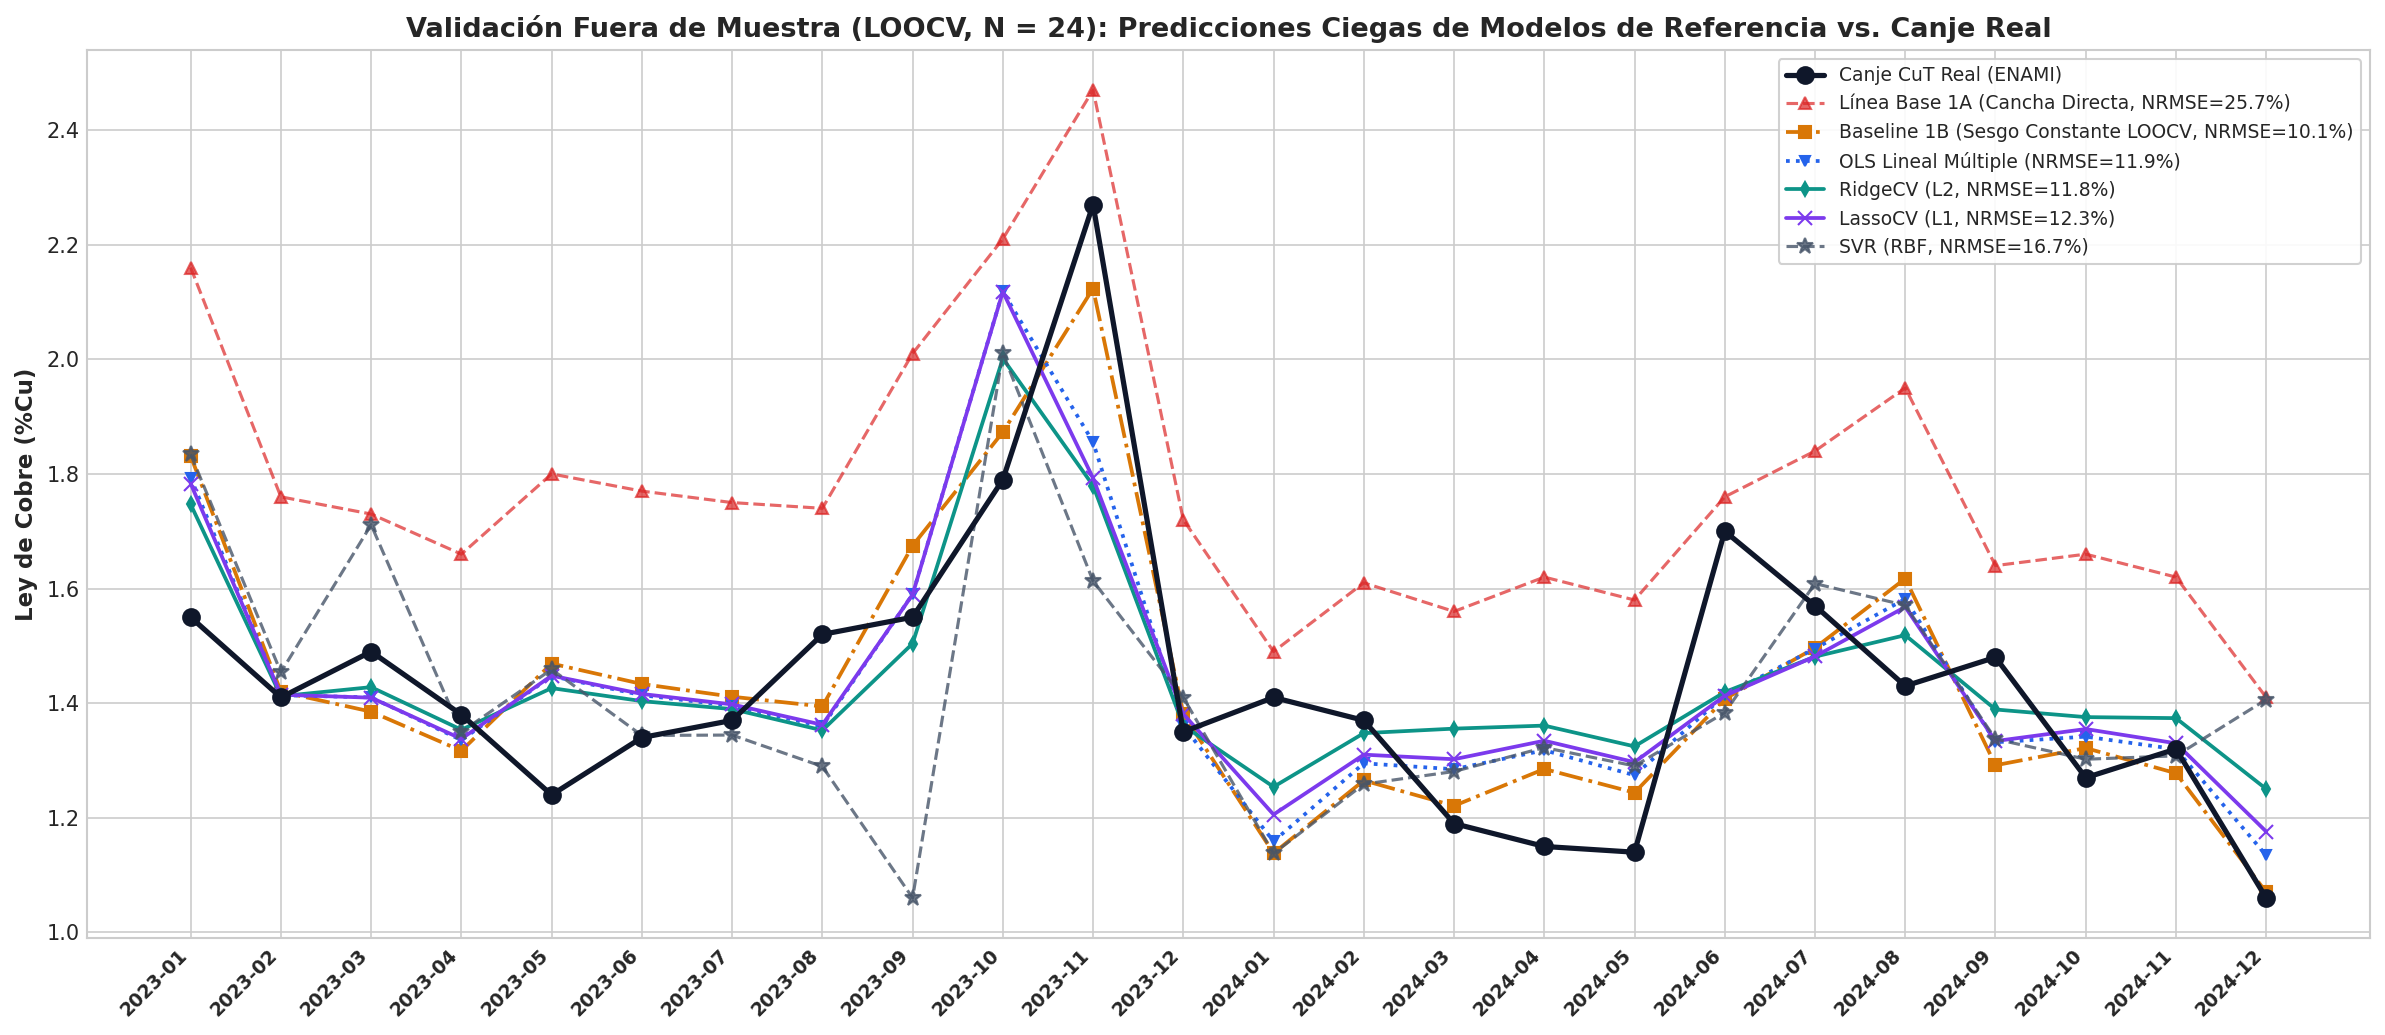

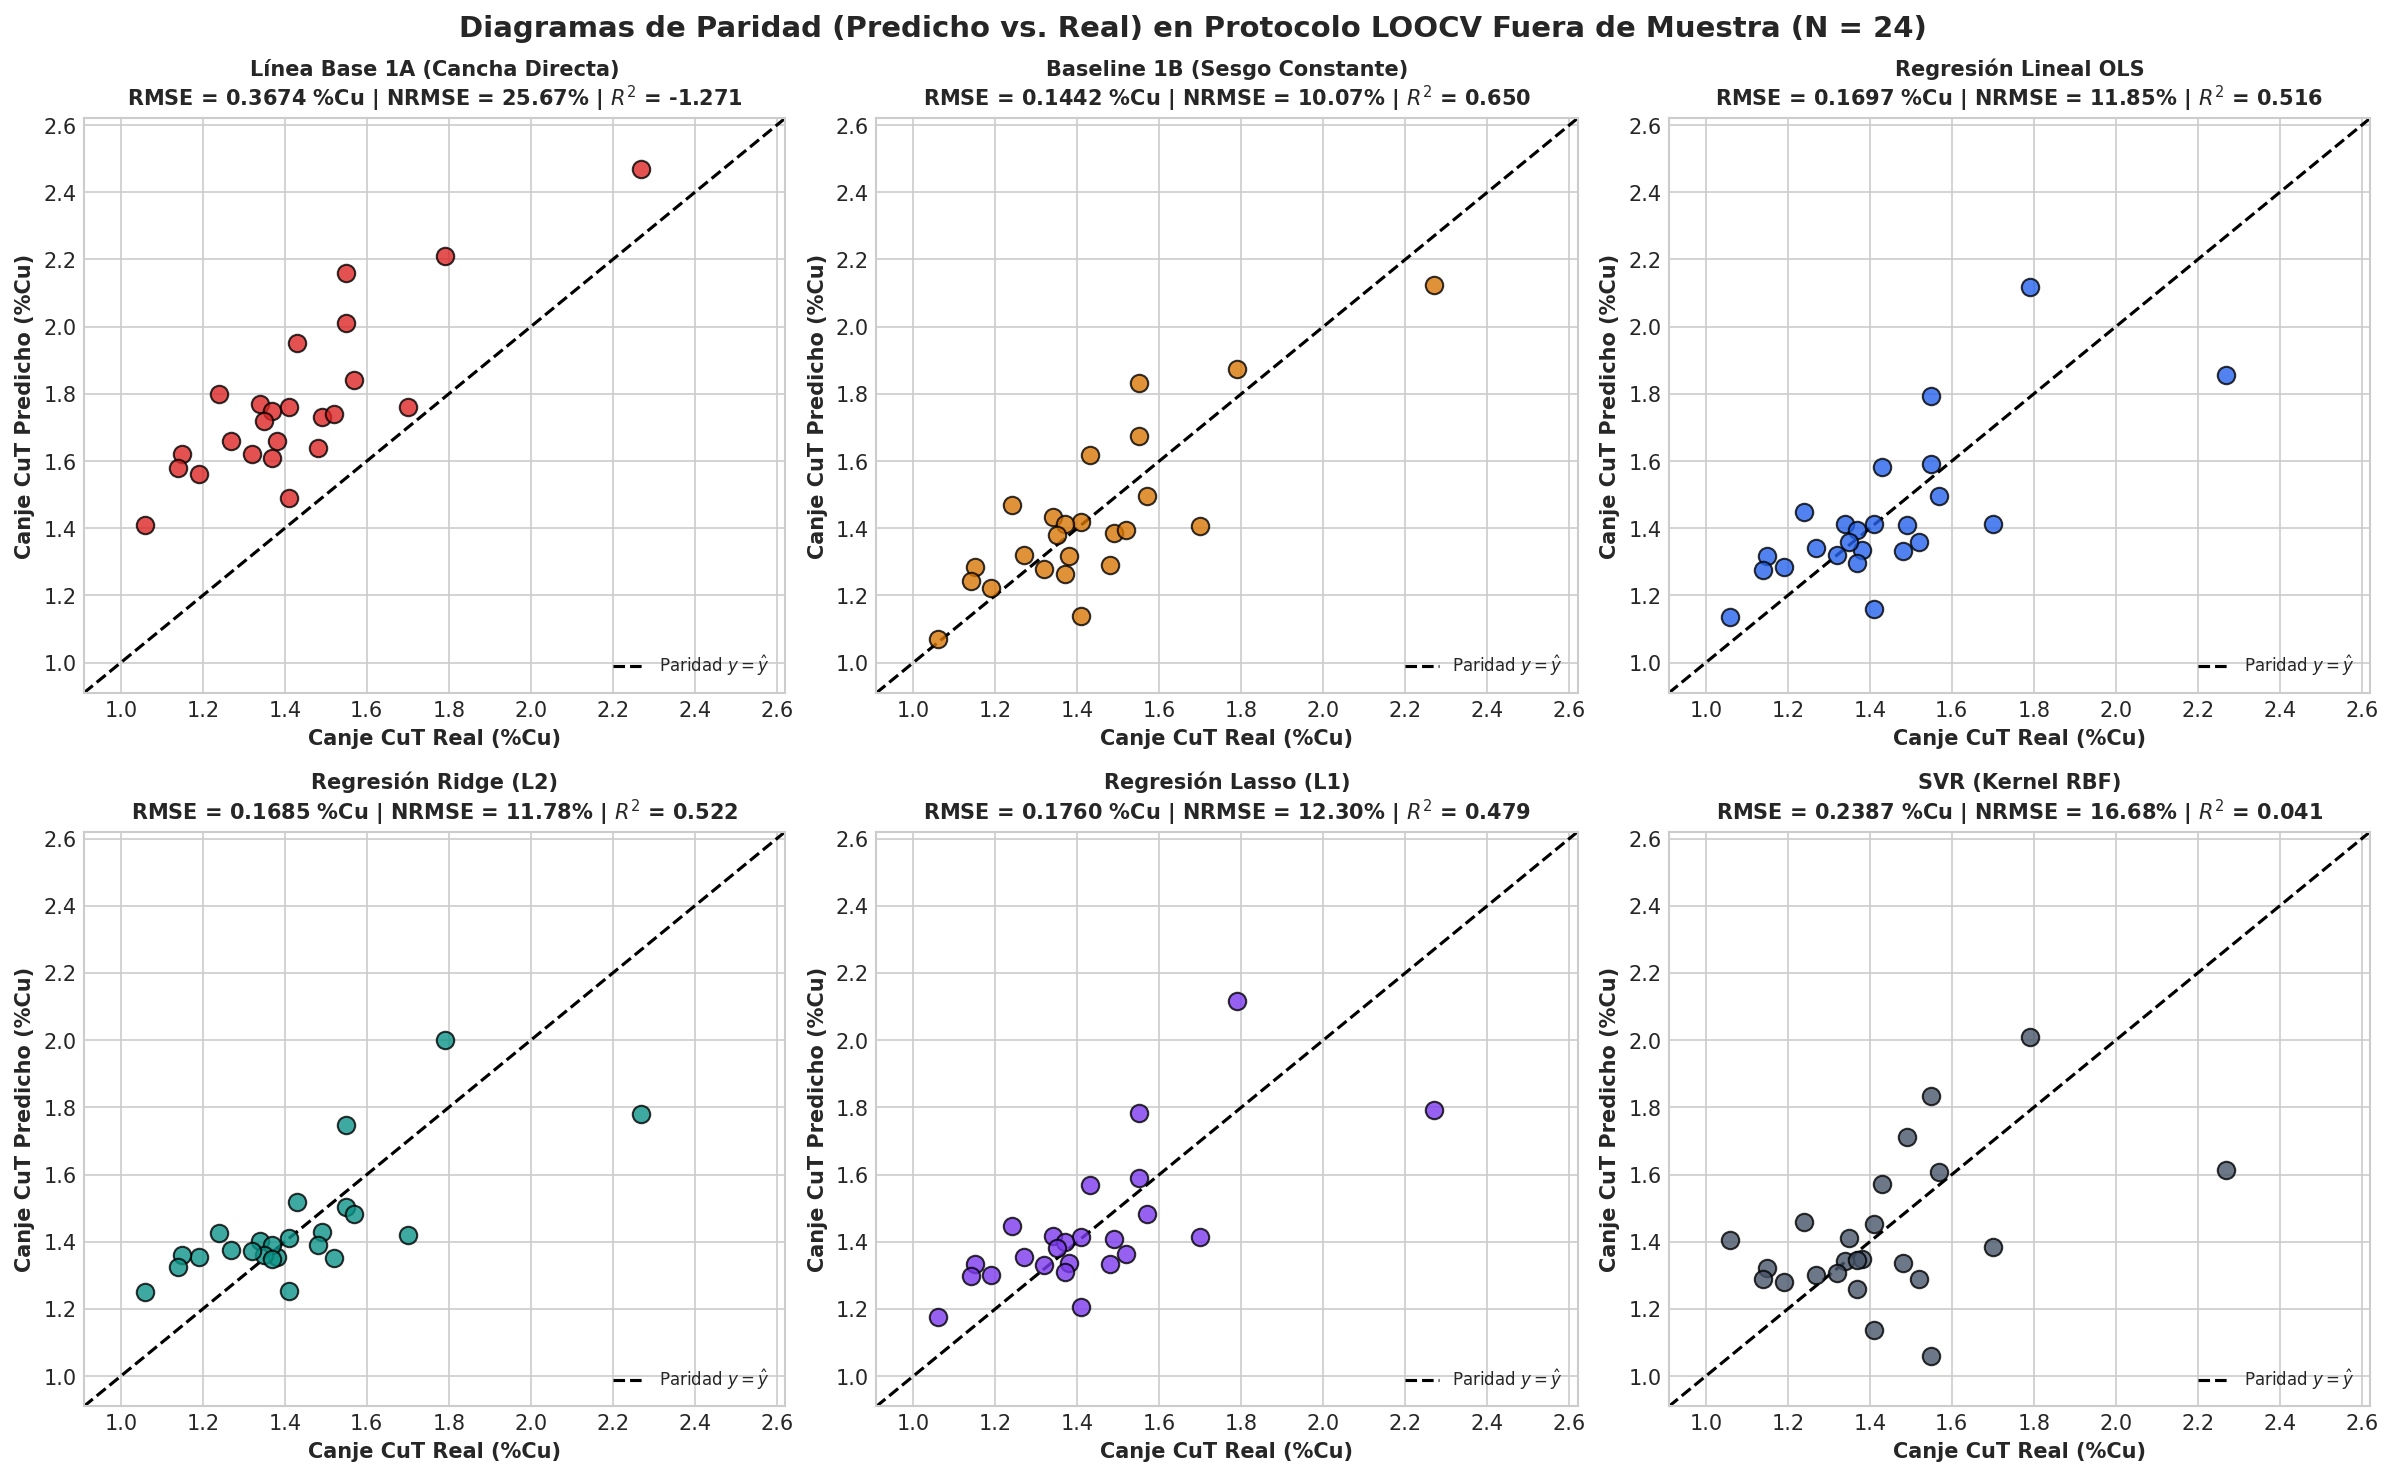

In [8]:
# 1. Serie Temporal de Predicciones OOS
fig, ax = plt.subplots(figsize=(16, 7))
x_idx = range(N)
ax.plot(x_idx, df_preds_std['Canje_CuT'], marker='o', markersize=8, color='#0F172A', linewidth=2.5, label='Canje CuT Real (ENAMI)', zorder=5)
ax.plot(x_idx, df_preds_std['Pred_Cancha_Directa'], marker='^', markersize=6, color='#DC2626', linestyle='--', linewidth=1.5, label='Línea Base 1A (Cancha Directa, NRMSE=25.7%)', alpha=0.7)
ax.plot(x_idx, df_preds_std['Pred_Sesgo_Constante_LOOCV'], marker='s', markersize=6, color='#D97706', linestyle='-.', linewidth=1.8, label='Baseline 1B (Sesgo Constante LOOCV, NRMSE=10.1%)')
ax.plot(x_idx, df_preds_std['Pred_OLS'], marker='v', markersize=5, color='#2563EB', linestyle=':', linewidth=1.8, label='OLS Lineal Múltiple (NRMSE=11.9%)')
ax.plot(x_idx, df_preds_std['Pred_Ridge'], marker='d', markersize=5, color='#0D9488', linestyle='-', linewidth=1.8, label='RidgeCV (L2, NRMSE=11.8%)')
ax.plot(x_idx, df_preds_std['Pred_Lasso'], marker='x', markersize=7, color='#7C3AED', linestyle='-', linewidth=1.8, label='LassoCV (L1, NRMSE=12.3%)')
ax.plot(x_idx, df_preds_std['Pred_SVR'], marker='*', markersize=8, color='#475569', linestyle='--', linewidth=1.5, label='SVR (RBF, NRMSE=16.7%)', alpha=0.8)

ax.set_xticks(x_idx)
ax.set_xticklabels(fechas, rotation=45, ha='right', fontweight='bold', fontsize=9)
ax.set_ylabel("Ley de Cobre (%Cu)", fontweight='bold')
ax.set_title("Validación Fuera de Muestra (LOOCV, N = 24): Predicciones Ciegas de Modelos de Referencia vs. Canje Real", fontsize=13, fontweight='bold')
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=9)
plt.tight_layout()
plt.show()

# 2. Diagramas de Paridad (Predicho vs Real)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
models_to_plot = [
    ('Pred_Cancha_Directa', 'Línea Base 1A (Cancha Directa)', '#DC2626'),
    ('Pred_Sesgo_Constante_LOOCV', 'Baseline 1B (Sesgo Constante)', '#D97706'),
    ('Pred_OLS', 'Regresión Lineal OLS', '#2563EB'),
    ('Pred_Ridge', 'Regresión Ridge (L2)', '#0D9488'),
    ('Pred_Lasso', 'Regresión Lasso (L1)', '#7C3AED'),
    ('Pred_SVR', 'SVR (Kernel RBF)', '#475569')
]

y_min, y_max = y_real.min() - 0.15, y_real.max() + 0.35

for idx, (col_m, title_m, col_color) in enumerate(models_to_plot):
    r, c = divmod(idx, 3)
    ax_p = axes[r, c]
    preds_m = df_preds_std[col_m].values
    
    ax_p.scatter(y_real, preds_m, color=col_color, s=70, edgecolors='black', alpha=0.8, zorder=4)
    ax_p.plot([y_min, y_max], [y_min, y_max], color='black', linestyle='--', linewidth=1.5, label=r'Paridad $y = \hat{y}$')
    
    err_m = y_real - preds_m
    rmse_m = np.sqrt(np.mean(err_m**2))
    nrmse_m = (rmse_m / np.mean(y_real)) * 100
    r2_m = 1 - (np.sum(err_m**2) / ss_tot)
    
    ax_p.set_xlim(y_min, y_max)
    ax_p.set_ylim(y_min, y_max)
    ax_p.set_title(f"{title_m}\nRMSE = {rmse_m:.4f} %Cu | NRMSE = {nrmse_m:.2f}% | $R^2$ = {r2_m:.3f}", fontsize=10, fontweight='bold')
    ax_p.set_xlabel("Canje CuT Real (%Cu)", fontsize=10)
    ax_p.set_ylabel("Canje CuT Predicho (%Cu)", fontsize=10)
    ax_p.legend(loc='lower right', fontsize=8)

plt.suptitle("Diagramas de Paridad (Predicho vs. Real) en Protocolo LOOCV Fuera de Muestra (N = 24)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

---
## 8. Matriz de Cierre y Transferencia Metodológica al Bloque 3

En cumplimiento estricto del marco metodológico (**Versión 4.0**), el presente **Bloque 2** certifica los siguientes resultados y contratos de salida:

| Requisito Metodológico | Resultado Concreto Certificado | Contrato para Bloques Siguientes |
| :--- | :---: | :--- |
| **1. Protocolo Cero Fuga** | `Pipeline` con escalado ajustado exclusivamente en los $23$ datos de entrenamiento. | Protocolo sellado para entrenar las Redes Neuronales en el **Bloque 3**. |
| **2. Líneas Base de Terreno** | Cancha Directa: $\text{NRMSE} = 25.67\%$, $R^2 = -1.2709$.<br>Sesgo Constante: $\text{NRMSE} = 10.07\%$, $R^2 = +0.6503$. | La RNA (Bloque 3) debe perforar el piso del **$10.07\%$** para justificar valor industrial. |
| **3. Modelos Regularizados** | OLS ($\text{NRMSE}=11.85\%$), Ridge ($\text{NRMSE}=11.78\%$), Lasso ($\text{NRMSE}=12.30\%$). | Coeficientes e hiperparámetros registrados en `LOG_HIPERPARAMETROS_BASELINES.csv`. |
| **4. Retención de CuS** | LassoCV conserva `Cancha_CuS` en **$24/24$ pliegues ($100\%$)** con $\beta \in [0.0124, 0.0627]$. | Justifica conservar ambas entradas en la RNA y realizar estudio de ablación en Bloque 4. |
| **5. Sensibilidad de Escalado** | `StandardScaler` y `RobustScaler` arrojan métricas prácticamente idénticas ($\Delta \text{RMSE} < 0.001\%$). | Valida `StandardScaler` como norma del proyecto sin distorsión por curtosis. |
| **6. Blindaje Buffered** | En `Buffered-LOOCV`, Lasso y ElasticNet mantienen $\text{NRMSE} \approx 12.3\%$. | Descarta que la precisión del modelo sea producto de inercia o fuga temporal. |
| **7. Contrato de Salida** | Generados `PREDICCIONES_OOS_BASELINES.csv/.xlsx` y logs asociados. | Listos para ser consumidos por el benchmarking unificado del **Bloque 4**. |

> **🚀 Dictamen del Bloque 2:** Entrenamiento de Modelos de Referencia (*Baselines*) formalmente **APROBADO Y SELLADO (METODOLOGÍA v4.0)**.  
> El repositorio se encuentra plenamente habilitado para ejecutar el **BLOQUE 3: Diseño, Optimización y Entrenamiento de Redes Neuronales Artificiales (RNA)** (`03_modelado_rna_loocv.ipynb`).